Net(
  (fc1): Linear(in_features=1, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (act): Tanh()
)
[Parameter containing:
tensor([[ 0.7341],
        [-0.9914],
        [-0.1784],
        [-0.2398],
        [ 0.5155],
        [-0.2276],
        [ 0.3676],
        [ 0.0067],
        [ 0.6961],
        [ 0.0441],
        [ 0.1697],
        [-0.6821],
        [-0.1402],
        [ 0.9496],
        [-0.5322],
        [ 0.9100],
        [ 0.6663],
        [-0.0443],
        [ 0.1738],
        [ 0.6073],
        [ 0.1348],
        [ 0.0266],
        [-0.2192],
        [-0.6560],
        [ 0.0538],
        [-0.7651],
        [-0.7484],
        [ 0.4660],
        [ 0.1760],
        [-0.3661],
        [ 0.9954],
        [ 0.3614]], requires_grad=True), Parameter containing:
tensor([ 0.4124, -0.4534,  0.9744, -0.9431, -0.0865, -0.6017,  0.9895, -0.1649,
         0.8243,  0.1809, -0.9742,  0.9348, 

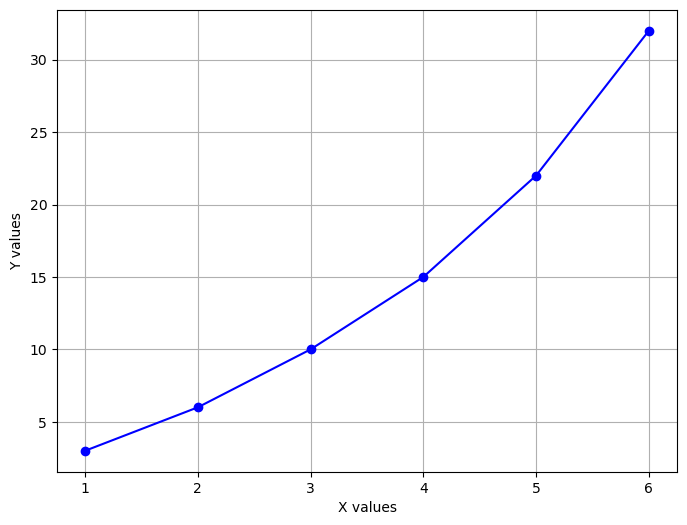

In [1]:
### Training with fancier version ###

import torch
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module): ## nn.Module class is used
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(1,32)   # in dim, out dim
        self.fc2 = nn.Linear(32,32)
        self.fc3 = nn.Linear(32,1)
        self.act = nn.Tanh()

    def forward(self, x):
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        x = self.fc3(x)              # no activation on the output: targets go up to 32
        return x

net = Net()

print(net)
print(list(net.parameters())) # parameters are randomized


#def criterion(out, label):
#    return (label - out)**2
criterion = nn.MSELoss()


optimizer = optim.SGD(net.parameters(), lr=0.0003, momentum=0.9)
#optimizer = optim.Adam(net.parameters(), lr=0.1)


data = [(1.0,3.0), (2.0,6.0), (3.0,10.0), (4.0,15.0), (5.0,22.0), (6.0,32.0)]

# Split data into x and y
x_values, y_values = zip(*data)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o', linestyle='-', color='b')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.grid(True)
plt.show()

Epoch 0 - loss: 285.05377197265625
Epoch 100 - loss: 0.043878644704818726
Epoch 200 - loss: 1.121335506439209
Epoch 300 - loss: 0.6564124226570129
Epoch 400 - loss: 0.0065258159302175045
Epoch 500 - loss: 0.002067931927740574
Epoch 600 - loss: 0.0014326547970995307
Epoch 700 - loss: 0.0005972183425910771
Epoch 800 - loss: 0.00033190843532793224
Epoch 900 - loss: 0.00017981363635044545
Epoch 1000 - loss: 0.0001107604693970643
Epoch 1100 - loss: 6.007785486872308e-05
Epoch 1200 - loss: 3.2266507332678884e-05
Epoch 1300 - loss: 1.7986652892432176e-05
Epoch 1400 - loss: 1.0242883035971317e-05
Epoch 1500 - loss: 5.7452784858469386e-06
Epoch 1600 - loss: 3.275185008533299e-06
Epoch 1700 - loss: 1.8274182593813748e-06
Epoch 1800 - loss: 1.0359642601542873e-06
Epoch 1900 - loss: 5.969610015199578e-07
Epoch 2000 - loss: 3.345041932334425e-07
Epoch 2100 - loss: 2.0062134353793226e-07
Epoch 2200 - loss: 1.2716957087377523e-07
Epoch 2300 - loss: 1.2969371709914412e-07
Epoch 2400 - loss: 1.25114070

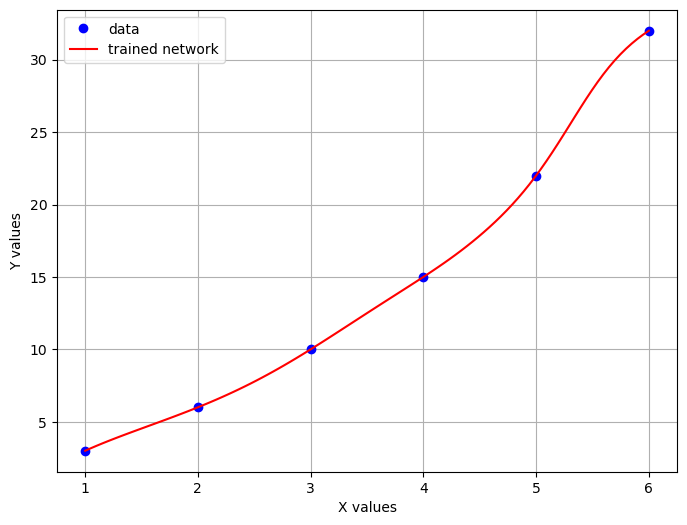

In [2]:
# all 6 points as tensors, used to measure the loss over the whole dataset
X_all = torch.FloatTensor(x_values).view(-1, 1)
Y_all = torch.FloatTensor(y_values).view(-1, 1)

for epoch in range(5000):
    for i, current_data in enumerate(data):
        X, Y = current_data
        X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])
        optimizer.zero_grad()   
        outputs = net(X)
        loss = criterion(outputs, Y)
        loss.backward()
        optimizer.step()    ## This line is equivalent to "W = W - lr* W.grad"

    # MSE over all 6 points (not just the last sample of the epoch)
    with torch.no_grad():
        total_loss = criterion(net(X_all), Y_all).item()
    if epoch % 100 == 0:
        print("Epoch {} - loss: {}".format(epoch, total_loss))
    if total_loss < 1e-8:   # well below the 1e-5 target, stop here
        break

print("Final epoch {} - loss: {}".format(epoch, total_loss))


### Test the trained network ###            
for i, current_data in enumerate(data):
    X, Y = current_data
    X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])  
    out = net(torch.FloatTensor(X))  
    print("when x = {}, y = {}".format(X, out))

### Plot the trained network against the data ###
with torch.no_grad():
    x_fine = torch.linspace(1, 6, 100).view(-1, 1)
    y_fine = net(x_fine)
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, 'bo', label='data')
plt.plot(x_fine.view(-1).numpy(), y_fine.view(-1).numpy(), 'r-', label='trained network')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.legend()
plt.grid(True)
plt.show()


In [3]:
X

tensor([6.])

In [4]:
for epoch in range(20):
    print(epoch)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


In [5]:
W = torch.tensor([1.0], requires_grad=True)
W = W*2
label = 1.0
loss = W*5 - label 
loss.backward()
W.grad

/tmp/ipykernel_708/353321738.py:6: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at aten/src/ATen/core/TensorBody.h:489.)
  W.grad
